
# EXERCISES E: Evaluations of Classification ML Techniques

N.B. The exercise 3 comes from examples given in <i>Hands-On Machine Learning 3rd Ed., A. Géron, O'Reilly, 2023, Chapter 3</i>, 
that were discussed during the course.

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Analysis of Binary Classifiers on Artificial 1D Datasets

In this exercise, we aim at better understanding the notions of recall and precision based on simple classification problems.

### 1.1 Build the datasets
(similar as in the preceding set of exercises)

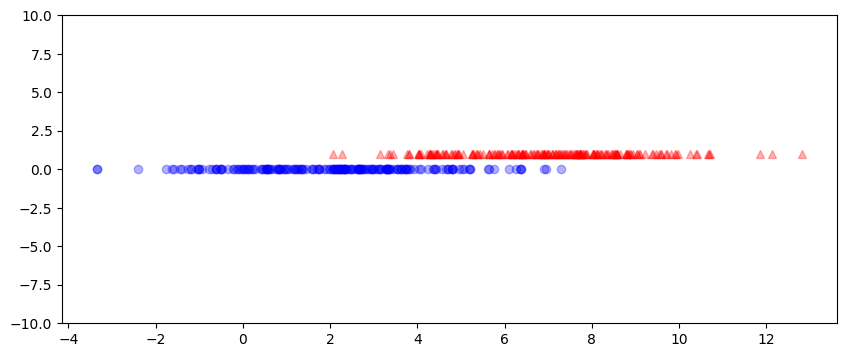

In [50]:
def gaussian_1D_generation(mean, standard_deviation,  N):
    X = (standard_deviation * np.random.randn(N) + mean).reshape(-1,1)
    return X

size_class_0 = 300
size_class_1 = 300

X_0 = gaussian_1D_generation(2, 2, size_class_0) 
X_1 = gaussian_1D_generation(7, 2, size_class_1)

Y_0 = np.zeros(size_class_0, dtype=int)
Y_1 = np.ones(size_class_1, dtype=int)

X = np.concatenate((X_0, X_1))
Y = np.concatenate((Y_0, Y_1))

X_train, X_valid, y_train, y_valid = train_test_split(X, Y, test_size=0.33, random_state=42)

plt.figure(figsize=(10, 4))
plt.ylim([-10,10])
plt.plot(X_train[y_train == 0], y_train[y_train == 0], "bo", alpha=0.3)
plt.plot(X_train[y_train == 1], y_train[y_train == 1], "r^", alpha=0.3)
plt.show()

# N.B: Here, by keeping the labels to 1 for the "r^ class" (class 1), and extending the y interval to -10,10, 
#      the representation of the two classes do not overlap. 

### 1.2 Classify with step functions  

Consider the generalizations/models in the plain form of a binary step function to decide the class ($0$ or $1$) for any point belonging to the line $\mathbb{R}$ : $$h_\theta(x) = \begin{cases}1 & \mathrm{if}\:sign \cdot x \geq bound\\0 & \mathrm{otherwise}\end{cases}$$
where $\theta=(sign,bound)$ with:
- $sign$ can be $-1$ or $1$, 
- $bound \in \mathbb{R}$ (the boundary decision).

Implement this simple parameterized step function and then:
- Test it for various values of $sign$ and $bound$ (with regard to the above dataset),
- Display the corresponding confusion matrix for each of them (hint: use the function `confusion_matrix` of `sklearn.metrics`).<br>
  The matrices are $\begin{pmatrix}\#TN & \#FP \\ \#FN & \#TP \end{pmatrix}$ like in the course slides.
- Understand the results.

## correction
## On implémente la fonction en escalier 

In [51]:
from sklearn.metrics import confusion_matrix

def step_function(X, sign, bound):
    return (sign * X >= bound).astype(int)
    

### on teste  différentes valeurs de sign et bound

In [52]:
parameters = [(1, 3), (1, 4), (1, 5),(1, 6), (1, 7), 
    (-1, -3), (-1, -4),(-1, -5),(-1, -6),(-1, -7)]

## On applique ensuite chaque modèle aux données de validation :

for sign, bound in parameters:
    y_pred = step_function(X_valid, sign, bound )
    print("sign =", sign, "bound =", bound)
    print("Predictions :", y_pred[:20])
    print()

sign = 1 bound = 3
Predictions : [[0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = 1 bound = 4
Predictions : [[0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = 1 bound = 5
Predictions : [[0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = 1 bound = 6
Predictions : [[0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = 1 bound = 7
Predictions : [[0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = -1 bound = -3
Predictions : [[1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]]

sign = -1 bound = -4
Predictions : [[1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]]

sign = -1 bound = -5
Predictions : [[1]
 [0]
 [0]
 

### Affichage de la matrice de confusion pour chaque modèle

In [53]:
for sign, bound in parameters:
    y_pred = step_function(X_valid, sign, bound)
    cm = confusion_matrix(y_valid, y_pred)

    print("--------------------------------")
    print("sign =", sign, "bound =", bound)
    print()
    print(cm)
    print()

--------------------------------
sign = 1 bound = 3

[[74 30]
 [ 1 93]]

--------------------------------
sign = 1 bound = 4

[[88 16]
 [ 4 90]]

--------------------------------
sign = 1 bound = 5

[[100   4]
 [ 10  84]]

--------------------------------
sign = 1 bound = 6

[[101   3]
 [ 30  64]]

--------------------------------
sign = 1 bound = 7

[[104   0]
 [ 58  36]]

--------------------------------
sign = -1 bound = -3

[[30 74]
 [93  1]]

--------------------------------
sign = -1 bound = -4

[[16 88]
 [90  4]]

--------------------------------
sign = -1 bound = -5

[[  4 100]
 [ 84  10]]

--------------------------------
sign = -1 bound = -6

[[  3 101]
 [ 64  30]]

--------------------------------
sign = -1 bound = -7

[[  0 104]
 [ 36  58]]



### affichage de  TN, FP, FN et TP

In [54]:
for sign, bound in parameters:
    y_pred = step_function( X_valid, sign, bound )

    cm = confusion_matrix(y_valid, y_pred)
    TN = cm[0, 0]
    FP = cm[0, 1]
    FN = cm[1, 0]
    TP = cm[1, 1]

    print("--------------------------------")
    print("sign =", sign, "bound =", bound)

    print("TN =", TN)
    print("FP =", FP)
    print("FN =", FN)
    print("TP =", TP)
    print()

--------------------------------
sign = 1 bound = 3
TN = 74
FP = 30
FN = 1
TP = 93

--------------------------------
sign = 1 bound = 4
TN = 88
FP = 16
FN = 4
TP = 90

--------------------------------
sign = 1 bound = 5
TN = 100
FP = 4
FN = 10
TP = 84

--------------------------------
sign = 1 bound = 6
TN = 101
FP = 3
FN = 30
TP = 64

--------------------------------
sign = 1 bound = 7
TN = 104
FP = 0
FN = 58
TP = 36

--------------------------------
sign = -1 bound = -3
TN = 30
FP = 74
FN = 93
TP = 1

--------------------------------
sign = -1 bound = -4
TN = 16
FP = 88
FN = 90
TP = 4

--------------------------------
sign = -1 bound = -5
TN = 4
FP = 100
FN = 84
TP = 10

--------------------------------
sign = -1 bound = -6
TN = 3
FP = 101
FN = 64
TP = 30

--------------------------------
sign = -1 bound = -7
TN = 0
FP = 104
FN = 36
TP = 58



### Intrepretation de resultat

### Choisir le meilleur sign

### 1.3 Plot the precision and recall curves

Use the value that seems the best for $sign$, and plot the recall and precision curves against $bound$
with $1$ as the predominant class (here, it is possible to use the functions `recall_score` and `precision_score` of `sklearn`).

### Faire varier bound

In [55]:
from sklearn.metrics import precision_score, recall_score

# On crée une liste de valeurs 
bounds = np.linspace(-5, 15, 300)

# puis on calcule precision et recall.
precisions = []
recalls = []
sign = 1

for bound in bounds:
    y_pred = step_function( X_valid, sign,bound)
    precision = precision_score( y_valid, y_pred, zero_division=0 )
    recall = recall_score( y_valid, y_pred, zero_division=0)
    precisions.append(precision)
    recalls.append(recall)

### tracer les courbes

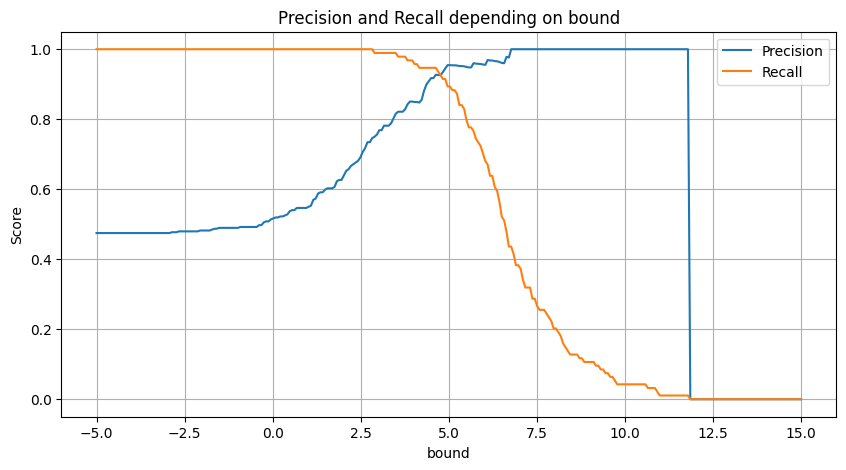

In [56]:
plt.figure(figsize=(10, 5))
plt.plot(bounds, precisions, label="Precision")
plt.plot(bounds, recalls, label="Recall")

plt.xlabel("bound")
plt.ylabel("Score")
plt.title("Precision and Recall depending on bound")

plt.legend()
plt.grid()
plt.show()

### Interpretation

### 1.4 Plot the ROC curves
Do the same as above but for the ROC curve, and print the AUC
(hint: use the functions `rec_curve` and `auc` of `sklearn`).

### Calculer TPR et FPR

In [57]:
bounds = np.linspace(-5, 15, 300)
TPR = []
FPR = []
sign = 1

for bound in bounds:
    y_pred = step_function(X_valid, sign, bound)
    cm = confusion_matrix(y_valid, y_pred)

    TN = cm[0, 0]
    FP = cm[0, 1]
    FN = cm[1, 0]
    TP = cm[1, 1]

    tpr = TP / (TP + FN) if (TP + FN) != 0 else 0
    fpr = FP / (FP + TN) if (FP + TN) != 0 else 0

    TPR.append(tpr)
    FPR.append(fpr)

### Calculer l'AUC

In [58]:
from sklearn.metrics import auc

roc_auc = auc(FPR, TPR)
print("AUC =", roc_auc)

AUC = 0.9750409165302782


### Tracer la ROC

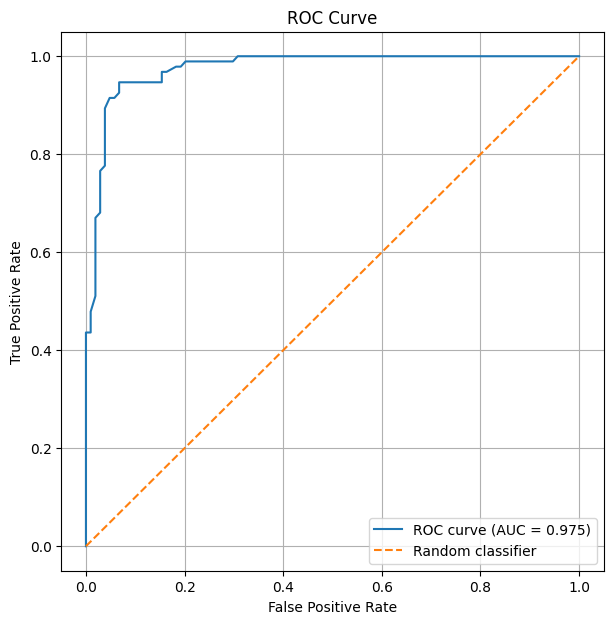

In [59]:
plt.figure(figsize=(7, 7))
plt.plot(FPR, TPR, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid()
plt.show()

### 1.5 Do the same as above with different datasets
Use different sizes of datasets, different balances between the two classes, different Gaussians, and different configurations of overlaps between classes. Implement other generation functions to get more configurations. Try to obtain different graph forms for the curves, and be sure you understand them.
 

In [60]:
def plot_precision_recall(X_valid, y_valid, sign=1):
    bounds = np.linspace(np.min(X_valid) - 1, np.max(X_valid) + 1, 300)
    precisions = []
    recalls = []

    for bound in bounds:
        y_pred = step_function(X_valid, sign, bound)

        precisions.append(
            precision_score(y_valid, y_pred, zero_division=0 )
        )
        recalls.append(
            recall_score( y_valid, y_pred, zero_division=0 )
        )

    plt.figure(figsize=(10, 5))
    plt.plot(bounds, precisions, label="Precision")
    plt.plot(bounds, recalls, label="Recall")

    plt.xlabel("bound")
    plt.ylabel("Score")
    plt.title("Precision and Recall depending on bound")
    plt.legend()
    plt.grid()
    plt.show()

In [61]:
def plot_roc(X_valid, y_valid, sign=1):
    bounds = np.linspace(np.min(X_valid) - 1, np.max(X_valid) + 1, 300)

    TPR = []
    FPR = []
    for bound in bounds:
        y_pred = step_function(X_valid, sign, bound)

        cm = confusion_matrix(y_valid, y_pred)
        TN = cm[0, 0]
        FP = cm[0, 1]
        FN = cm[1, 0]
        TP = cm[1, 1]

        tpr = TP / (TP + FN) if TP + FN > 0 else 0
        fpr = FP / (FP + TN) if FP + TN > 0 else 0
        TPR.append(tpr)
        FPR.append(fpr)

    roc_auc = auc(FPR, TPR)
    plt.figure(figsize=(7, 7))
    plt.plot(FPR, TPR, label=f"ROC (AUC = {roc_auc:.3f})")

    plt.plot([0, 1], [0, 1], "--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid()
    plt.show()
    print("AUC =", roc_auc)

### Dataset initial fourni dans l'énoncé

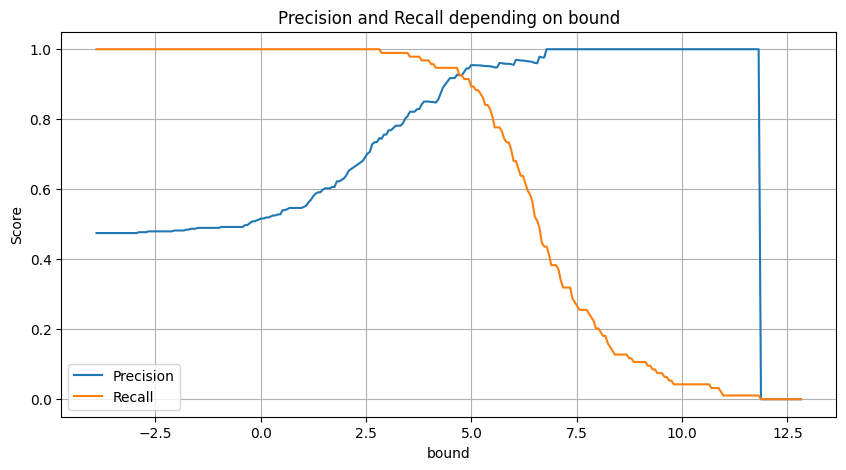

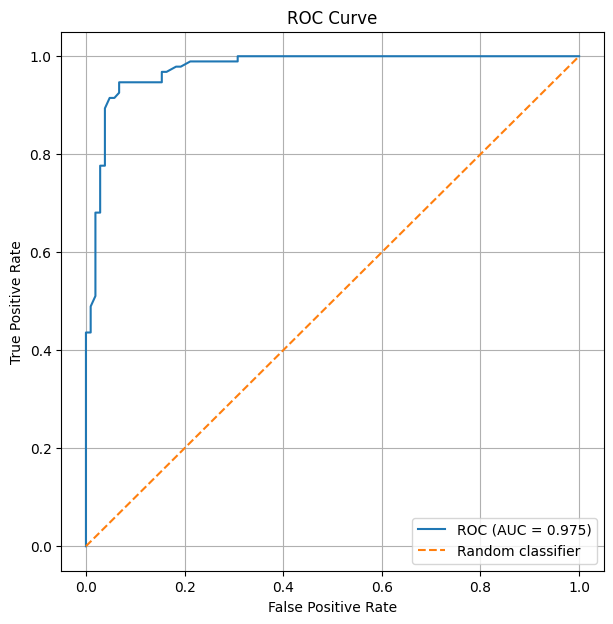

AUC = 0.9750920621931259


In [62]:
X_train, X_valid, y_train, y_valid = train_test_split(X, Y, test_size=0.33, random_state=42)
plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)

### classes très séparées

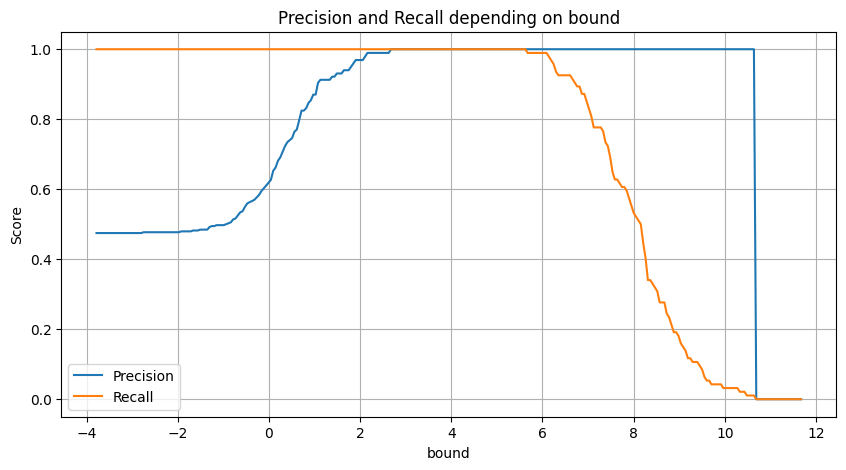

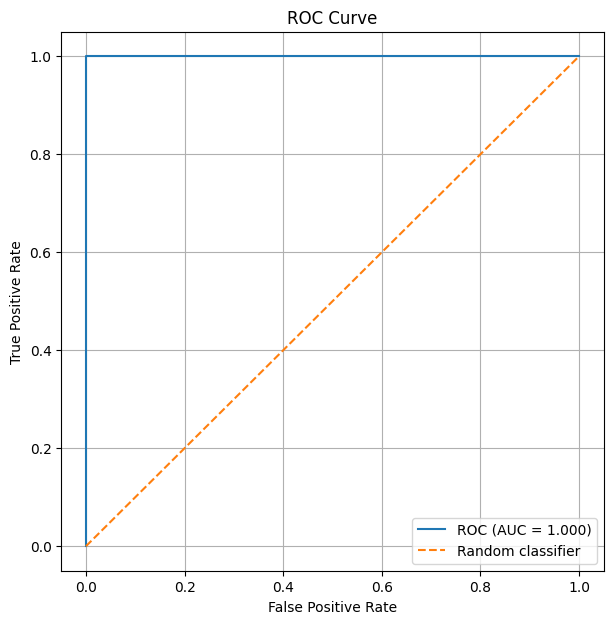

AUC = 1.0


In [63]:
def generate_dataset_1():
    size_class_0 = 300
    size_class_1 = 300

    X_0 = gaussian_1D_generation(0, 1, size_class_0)
    X_1 = gaussian_1D_generation(8, 1, size_class_1 )
    Y_0 = np.zeros(size_class_0, dtype=int)
    Y_1 = np.ones(size_class_1, dtype=int )
    X = np.concatenate((X_0, X_1))
    Y = np.concatenate((Y_0, Y_1))
    return train_test_split(X, Y, test_size=0.33, random_state=42)

X_train, X_valid, y_train, y_valid = generate_dataset_1()
plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)

### Classes qui se chevauchent fortement

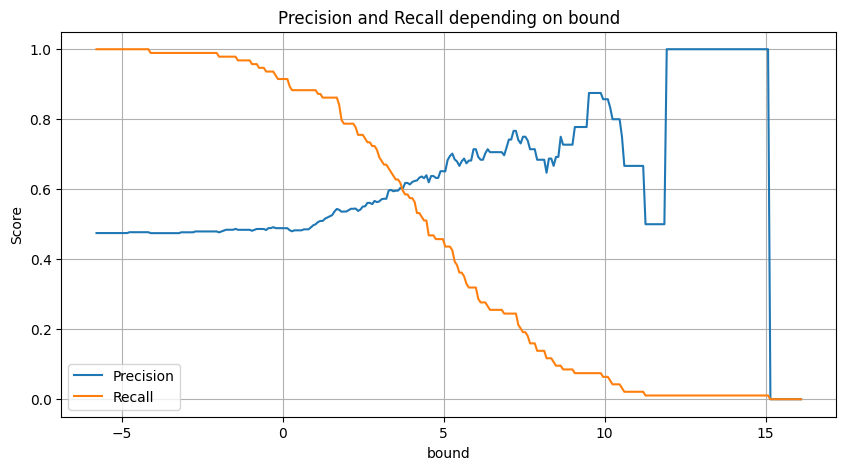

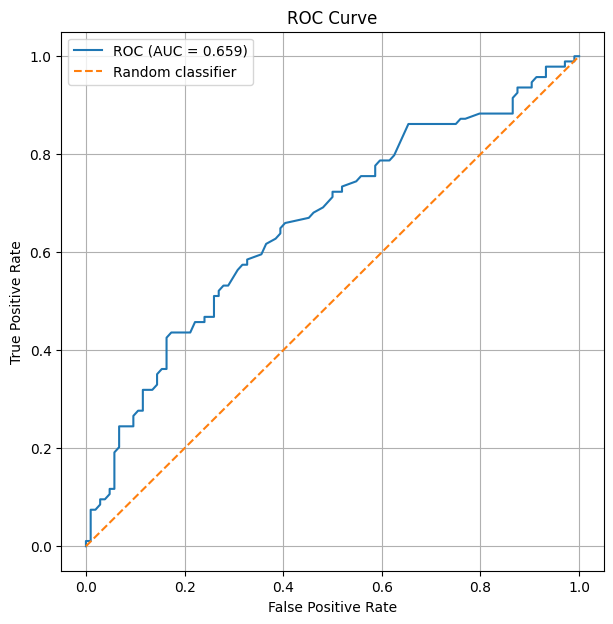

AUC = 0.6594721767594108


In [64]:
def generate_dataset_2():
    size_class_0 = 300
    size_class_1 = 300

    X_0 = gaussian_1D_generation(3, 3, size_class_0)
    X_1 = gaussian_1D_generation(5, 3, size_class_1 )
    Y_0 = np.zeros(size_class_0, dtype=int )
    Y_1 = np.ones(size_class_1, dtype=int)
    X = np.concatenate((X_0, X_1))
    Y = np.concatenate((Y_0, Y_1))
    return train_test_split(X, Y, test_size=0.33, random_state=42)
X_train, X_valid, y_train, y_valid = generate_dataset_2()

plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)


### Classes déséquilibrées

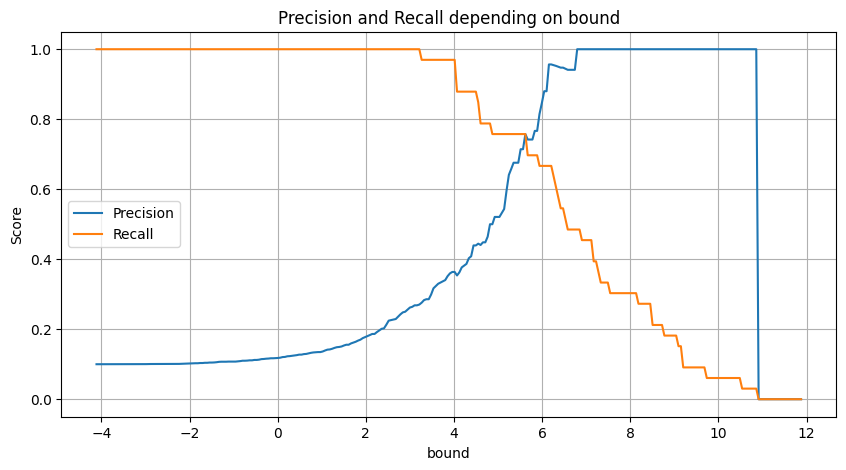

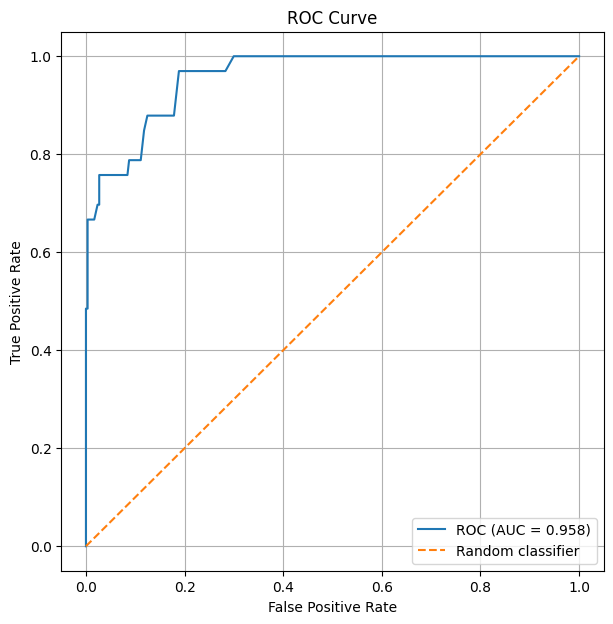

AUC = 0.9584226099377615


In [65]:
def generate_dataset_3():
    size_class_0 = 900
    size_class_1 = 100

    X_0 = gaussian_1D_generation(2, 2, size_class_0)
    X_1 = gaussian_1D_generation(7, 2, size_class_1)
    Y_0 = np.zeros(size_class_0, dtype=int)
    Y_1 = np.ones( size_class_1, dtype=int )
    X = np.concatenate((X_0, X_1))
    Y = np.concatenate((Y_0, Y_1))

    return train_test_split(X, Y, test_size=0.33, random_state=42, stratify=Y)

X_train, X_valid, y_train, y_valid = generate_dataset_3()
plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)

Classes presque parfaitement séparées

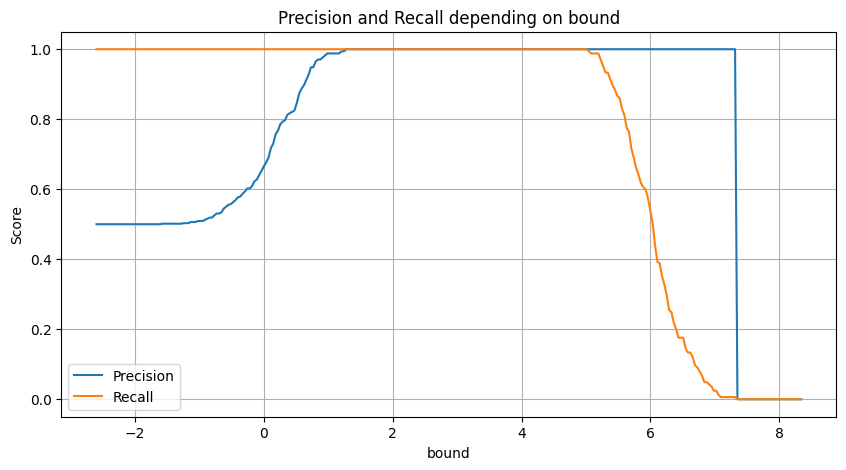

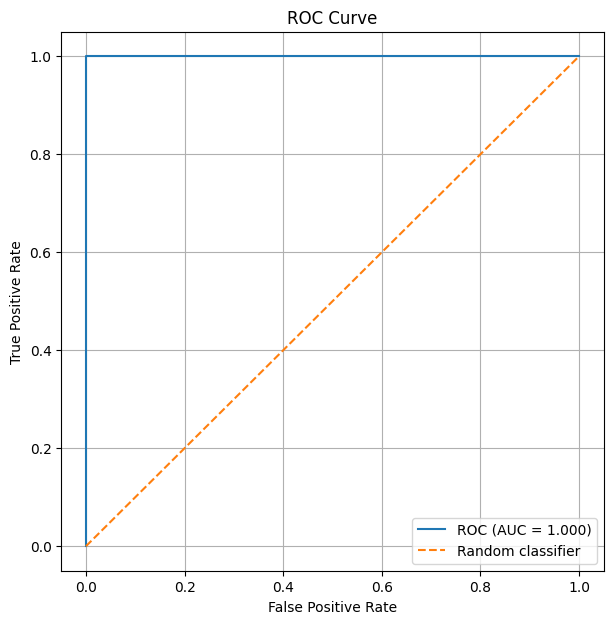

AUC = 1.0


In [66]:
def generate_dataset_4():
    size_class_0 = 500
    size_class_1 = 500

    X_0 = gaussian_1D_generation(0, 0.5, size_class_0)
    X_1 = gaussian_1D_generation( 6, 0.5, size_class_1)
    Y_0 = np.zeros(size_class_0, dtype=int)
    Y_1 = np.ones(size_class_1, dtype=int)
    X = np.concatenate((X_0, X_1))
    Y = np.concatenate((Y_0, Y_1))
    return train_test_split(X, Y, test_size=0.33, random_state=42)

X_train, X_valid, y_train, y_valid = generate_dataset_4()
plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)

## 2. Classification of images of handwritten digits (MNIST)

The purpose of this classic exercise is to train classifiers to distinguish handwritten digits based on the MNIST dataset, i.e. images 28x28 of the 10 possible digits.

### 2.1 Load and explore the dataset

Use the code below to download MNIST and store it into the variable mnist.

In [67]:
from sklearn.datasets import fetch_openml
from matplotlib import pyplot as plt
mnist = fetch_openml('mnist_784', as_frame=False) #Numpy arrays instead of Pandas DataFrames

In [68]:
print(mnist.keys())

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])


In [69]:
mnist['data']

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

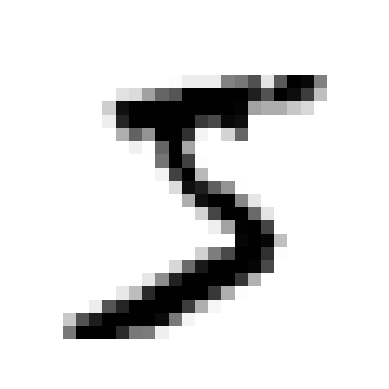

In [70]:
def plot_digit(image_data): 
    image = image_data.reshape(28, 28) 
    plt.imshow(image, cmap="binary") 
    plt.axis("off")

some_digit = mnist['data'][0] 
plot_digit(some_digit) 
plt.show()

### 2.2 Train classifiers with reduced datasets

1. Apply a partition of the dataset to create a training and a test set (80%/20%).
2. Since a full training on all the images of the training dataset can be pretty long, start by extracting only a fraction of it, like $\frac{1}{64}$. This smaller dataset will make the experiments much quicker. Check the size of the obtained training dataset.
3. Train a classifier using, e.g.,`SGDClassifier`.

### 2.3 Obtain and plot the confusion matrices
1. Use `confusion_matrix` of `sklearn.metrics` as well as `matshow` of `matplot` to visualize the matrices.
2. Study the high values of errors in the matrices and the cases that produce them.

### 2.4 Do the same as above with different hyperparameters
Use different hyperparameters to improve the obtained confusion matrices.

### 2.5 (Subsidiary) Use learning curves to determine how much data is needed 

Plot the error curves using the training set size against the error under the form of zero-one loss (the ratio of errors): one curve for the results with the training set, and the other curve with the test set.<br> 
Remark: the learning will take more and more time, so be careful of the required computation time.

Here we see that for small datasets (lower than 1000 instances), there is almost no error on the training set but a strong overfitting. Given the learning curve, it seems reasonable to assume that more data will help to slightly improve the performances, but not that much because the generalization gap is already pretty small.